# Which satellite inputs predict maize yield best?

Let's compare a few simple models using the same **1,880 Zimbabwe fields from the 2023 harvest**. Each model predicts maize yield in **tonnes per hectare (t/ha)**; one tonne is 1,000 kg.

We will look at the data, compare the input groups, and test predictions in new locations. We first compare monthly inputs, then add seasonal summaries in Section 9 to see whether keeping the month-by-month detail helps. Every Ridge model chooses its regularization strength through cross-validation, with separate fields kept aside for evaluation.


## 1. Start with the data

Each field has one yield measurement and up to nine months of satellite measurements, from October 2022 to June 2023. A field remains **one training example**, even though it has several months of data.

We keep the project's eligible 2023 fields with at least four usable months. The 2022 harvest is excluded because important growing-season images are missing. The code below opens the database without changing it and checks that the field IDs and yields match the project's saved data and split files.


In [1]:
import hashlib
import json
import os
import platform
import time
from pathlib import Path

os.environ.setdefault("MPLCONFIGDIR", "/tmp/cropyield_mpl")
for variable in ["VECLIB_MAXIMUM_THREADS", "OMP_NUM_THREADS", "OPENBLAS_NUM_THREADS"]:
    os.environ.setdefault(variable, "4")
import duckdb
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import scipy
import sklearn
from IPython.display import HTML, Markdown, display
from scipy.linalg import eigh
from scipy.stats import spearmanr
from sklearn.linear_model import Ridge
from sklearn.preprocessing import StandardScaler
from threadpoolctl import threadpool_limits

%matplotlib inline
blas_threads = threadpool_limits(limits=4)

ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "sql/schema.sql").exists())
DB = ROOT / "data/cropyield.duckdb"
OUT = ROOT / "notebook/baseline_results"
OUT.mkdir(parents=True, exist_ok=True)
COHORT = "zimbabwe_lacuna_2022_2023"
SEED = 20261029
ALPHAS = np.logspace(-3, 9, 25)
FAMILIES = {"s1_cc2km": "New village", "s2_region": "New region"}
N_BOOT = 2000
pd.set_option("display.max_columns", 20)
pd.set_option("display.max_colwidth", None)
pd.set_option("display.max_rows", 100)
pd.set_option("display.precision", 4)
plt.rcParams.update({"figure.dpi": 120, "axes.spines.top": False, "axes.spines.right": False,
                     "axes.grid": True, "grid.alpha": 0.18, "font.size": 10})

def savefig(name):
    plt.savefig(OUT / f"{name}.png", dpi=180, bbox_inches="tight", facecolor="white")
    plt.show()
    plt.close()


# Short labels for plots; the input table below explains what each group means.
MODEL_LABELS = {
    "Training mean": "Training mean",
    "Monthly availability": "Image availability only",
    "NDVI monthly": "NDVI",
    "GCVI monthly": "GCVI",
    "MTCI monthly": "MTCI",
    "NDVI705 monthly": "NDVI705",
    "NDVI740 monthly": "NDVI740",
    "All indices monthly": "All five indices",
    "Monthly bands": "Ten spectral bands",
    "MOSAIKS field monthly": "MOSAIKS: field pixel",
    "MOSAIKS chip monthly": "MOSAIKS: surrounding image",
    "CV-selected satellite": "Input chosen by inner CV",
}

def show_table(frame):
    display(HTML(frame.to_html(index=False, float_format=lambda value: f"{value:.3f}")))


In [2]:
with duckdb.connect(str(DB), read_only=True) as con:
    labels = con.execute("""
        SELECT obs_id, year, yield_kg_ha / 1000.0 AS yield_t_ha, latitude, longitude
        FROM labels WHERE cohort = ? AND year = 2023 AND include_primary
        ORDER BY obs_id
    """, [COHORT]).df().set_index("obs_id")
    monthly = con.execute("""
        SELECT m.* EXCLUDE (yield_kg_ha), b.field_pixels, b.missing
        FROM monthly m JOIN labels l USING (obs_id)
        LEFT JOIN monthly_bands b USING (obs_id, month)
        WHERE l.cohort = ? AND l.year = 2023 AND l.include_primary
        ORDER BY m.obs_id, m.month
    """, [COHORT]).df().set_index(["obs_id", "month"])
    build_info = con.execute("""SELECT built_at, git_commit, n_labels, n_embeddings, mosaiks_features
                                 FROM build_info""").df()

clear_counts = monthly["missing"].eq(False).groupby(level="obs_id").sum()
labels = labels.loc[clear_counts.reindex(labels.index).ge(4)]
IDS = labels.index
MONTHS = pd.period_range("2022-10", "2023-06", freq="M").astype(str).tolist()
GRID = pd.MultiIndex.from_product([IDS, MONTHS], names=["obs_id", "month"])
assert monthly.index.is_unique and IDS.is_unique
monthly = monthly.reindex(GRID)
y = labels.yield_t_ha.to_numpy(dtype=float)
assert len(IDS) == 1880 and np.isfinite(y).all()

manifest = json.loads((ROOT / "data/splits/manifest.json").read_text())
label_path = ROOT / "data/processed/labels_v1.parquet"
assert hashlib.sha256(label_path.read_bytes()).hexdigest() == manifest["labels_sha256"]
frozen_labels = pd.read_parquet(label_path).set_index("obs_id").loc[IDS]
np.testing.assert_allclose(y, frozen_labels.yield_kg_ha.to_numpy() / 1000)
assert frozen_labels.include_primary.all()
splits, split_audit = {}, []
for family in FAMILIES:
    path = ROOT / f"data/splits/{COHORT}__{family}.csv"
    digest = hashlib.sha256(path.read_bytes()).hexdigest()
    assert digest == manifest["files"][path.name]["sha256"]
    split = pd.read_csv(path).set_index("obs_id")
    assert split.index.is_unique and set(split.index) == set(IDS)
    split = split.loc[IDS]
    assert split["repeat"].eq(0).all() and split.groupby("group_id").fold.nunique().eq(1).all()
    assert set(split.fold) == set(range(5))
    for fold in range(5):
        test = split.fold.eq(fold)
        assert set(split.loc[test, "group_id"]).isdisjoint(split.loc[~test, "group_id"])
        split_audit.append({"protocol": FAMILIES[family], "outer_fold": fold,
                            "train_fields": int((~test).sum()), "test_fields": int(test.sum()),
                            "test_groups": split.loc[test, "group_id"].nunique()})
    splits[family] = split


print(f"Ready: {len(IDS):,} fields, each with one yield target and {len(MONTHS)} monthly slots.")
print("Checks passed: field IDs, yield values, and saved spatial splits agree with the project files.")


Ready: 1,880 fields, each with one yield target and 9 monthly slots.
Checks passed: field IDs, yield values, and saved spatial splits agree with the project files.


**What does the sample look like?** On the left, the bars count fields at different yield levels; the dashed line marks the sample mean. On the right, each bar shows the percentage of fields with all ten spectral bands available that month. A spectral band is a measurement of reflected light within a particular wavelength range.


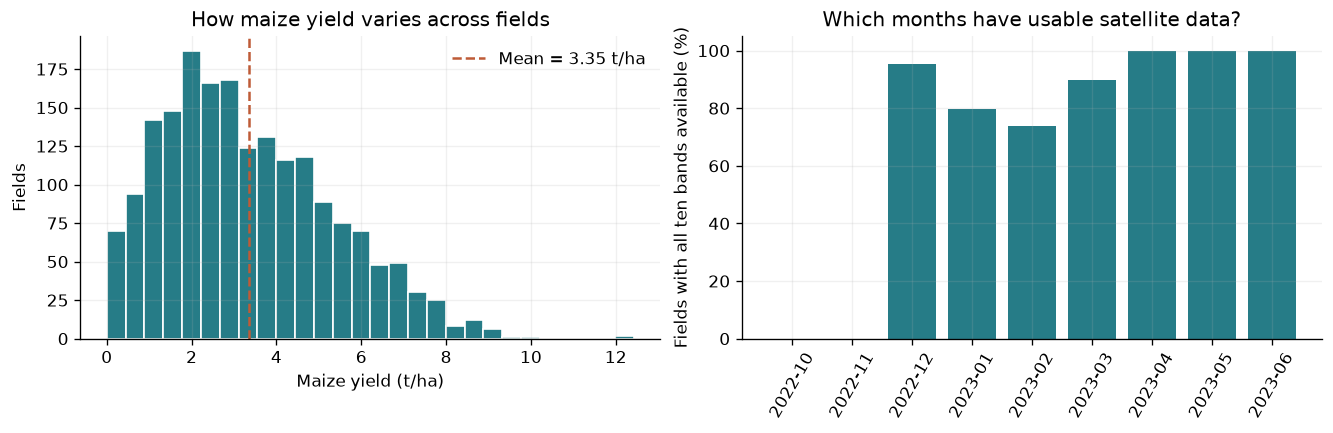

In [3]:
fig, axes = plt.subplots(1, 2, figsize=(11, 3.5), layout="constrained")
axes[0].hist(y, bins=28, color="#267c87", edgecolor="white")
axes[0].axvline(y.mean(), color="#be5b37", linestyle="--", label=f"Mean = {y.mean():.2f} t/ha")
axes[0].set(xlabel="Maize yield (t/ha)", ylabel="Fields", title="How maize yield varies across fields")
axes[0].legend(frameon=False)
band_columns = ["b02", "b03", "b04", "b05", "b06", "b07", "b08", "b8a", "b11", "b12"]
availability = monthly[band_columns].notna().all(axis=1).groupby(level="month").mean().reindex(MONTHS)
axes[1].bar(np.arange(9), availability * 100, color="#267c87")
axes[1].set(xticks=np.arange(9), xticklabels=MONTHS, ylim=(0, 105), ylabel="Fields with all ten bands available (%)",
            title="Which months have usable satellite data?")
axes[1].tick_params(axis="x", rotation=60)
savefig("01_yield_and_coverage")


Most fields yield roughly 1–5 t/ha, with a smaller number of higher-yield fields. October and November have no usable images in this database. We keep their calendar positions when arranging the data, but remove their empty measurement columns during model fitting.


## 2. Choose one input group at a time

All rows in the table below predict the **same yield target**. What changes is the information given to the model.

The satellite bands include visible light and **near-infrared (NIR)** light, which lies just beyond visible red. The **red edge** is the transition between red and near-infrared. Vegetation indices combine these light measurements into a few numerical summaries.

**MOSAIKS** converts an image into numerical features using fixed random image filters. Here it produces 1,024 values per month. The *field* version uses the sampled field pixel; the *surrounding-image* version uses the full image patch around it. Zimbabwe locations are points, so “field” does not mean a traced field boundary.

The training-mean and image-availability models are reference points: they tell us how well we can predict without using the measured satellite values.


In [4]:
BANDS = ["b02", "b03", "b04", "b05", "b06", "b07", "b08", "b8a", "b11", "b12"]
INDICES = ["ndvi", "gcvi", "mtci", "ndvi705", "ndvi740"]
n, m = len(IDS), len(MONTHS)
models = {}

# Axis order is field, month, feature; the feature names make that order explicit.
def add_model(name, cube, feature_names, clip=False, add_flags=True):
    cube = np.array(cube, dtype=float, copy=True)
    cube[~np.isfinite(cube)] = np.nan
    flags = np.isfinite(cube).all(axis=2).astype(float)
    names = [f"{month}__{feature}" for month in MONTHS for feature in feature_names]
    models[name] = {"X": cube.reshape(n, -1), "flags": flags if add_flags else None,
                    "clip": clip, "columns": names}

band_cube = monthly[BANDS].to_numpy(dtype=float).reshape(n, m, len(BANDS))
add_model("Monthly bands", band_cube, BANDS)
index_cube = monthly[INDICES].to_numpy(dtype=float).reshape(n, m, len(INDICES))
for j, index in enumerate(INDICES):
    add_model(f"{index.upper()} monthly", index_cube[:, :, j:j+1].copy(), [index], clip=True)
add_model("All indices monthly", index_cube, INDICES, clip=True)

for column, name in [("mosaiks_field", "MOSAIKS field monthly"), ("mosaiks_chip", "MOSAIKS chip monthly")]:
    values = monthly[column]
    present = values.map(lambda v: isinstance(v, (list, tuple, np.ndarray))).to_numpy()
    widths = {len(v) for v in values[present]}
    assert widths == {1024}
    matrix = np.full((len(GRID), 1024), np.nan)
    matrix[present] = np.stack(values[present].to_list())
    add_model(name, matrix.reshape(n, m, 1024), [f"{column}_{j:04d}" for j in range(1024)])

band_flags = np.isfinite(band_cube).all(axis=2).astype(float)
models["Monthly availability"] = {"X": band_flags, "flags": None, "clip": False,
                                   "columns": [f"available_{month}" for month in MONTHS]}
ORDER = ["Training mean", "Monthly availability", *[f"{x.upper()} monthly" for x in INDICES],
         "All indices monthly", "Monthly bands", "MOSAIKS field monthly", "MOSAIKS chip monthly"]
models = {name: models[name] for name in ORDER if name != "Training mean"}
SIGNAL_MODELS = [name for name in models if name != "Monthly availability"]
SELECTOR = "CV-selected satellite"

inventory = []
for name, data in models.items():
    inventory.append({"model": name, "monthly_signal_columns": data["X"].shape[1],
                      "availability_flags": 0 if data["flags"] is None else data["flags"].shape[1],
                      "all_missing_columns_in_this_copy": int(np.isnan(data["X"]).all(axis=0).sum()),
                      "missing_signal_values_pct": 100 * np.isnan(data["X"]).mean(),
                      "training_percentile_clip": data["clip"]})

input_descriptions = {
    "Training mean": (0, "No satellite input: predict the mean yield of the training fields."),
    "Monthly availability": (1, "A yes/no indicator of whether all ten bands are available each month."),
    "NDVI monthly": (1, "Normalized Difference Vegetation Index: compares near-infrared and red light."),
    "GCVI monthly": (1, "Green Chlorophyll Vegetation Index: combines near-infrared and green light."),
    "MTCI monthly": (1, "MERIS Terrestrial Chlorophyll Index: combines near-infrared, red-edge, and red light."),
    "NDVI705 monthly": (1, "An NDVI variant using the 705 nm red-edge band instead of red."),
    "NDVI740 monthly": (1, "An NDVI variant using the 740 nm red-edge band instead of red."),
    "All indices monthly": (5, "All five vegetation indices together."),
    "Monthly bands": (10, "The ten reflected-light measurements, before converting them to indices."),
    "MOSAIKS field monthly": (1024, "Image features computed over the sampled field pixel."),
    "MOSAIKS chip monthly": (1024, "Image features computed over the surrounding image patch."),
}
input_table = pd.DataFrame([
    {"Model input": MODEL_LABELS[name], "Values per month": input_descriptions[name][0],
     "What this model sees": input_descriptions[name][1]} for name in ORDER
])
show_table(input_table)


Model input,Values per month,What this model sees
Training mean,0,No satellite input: predict the mean yield of the training fields.
Image availability only,1,A yes/no indicator of whether all ten bands are available each month.
NDVI,1,Normalized Difference Vegetation Index: compares near-infrared and red light.
GCVI,1,Green Chlorophyll Vegetation Index: combines near-infrared and green light.
MTCI,1,"MERIS Terrestrial Chlorophyll Index: combines near-infrared, red-edge, and red light."
NDVI705,1,An NDVI variant using the 705 nm red-edge band instead of red.
NDVI740,1,An NDVI variant using the 740 nm red-edge band instead of red.
All five indices,5,All five vegetation indices together.
Ten spectral bands,10,"The ten reflected-light measurements, before converting them to indices."
MOSAIKS: field pixel,1024,Image features computed over the sampled field pixel.


To turn the monthly measurements into model inputs, we put them side by side. For example, the NDVI model gets separate columns for December NDVI, January NDVI, and so on; it does not average them over the season. Here **nm means nanometres**, the wavelength unit used to name the red-edge bands.

Missing images stay marked as missing until preprocessing. Each satellite model also receives monthly availability indicators, so an imputed value can be distinguished from an observed one. We leave out Presto because the stored embeddings do not have a monthly time axis.


## 3. Test on locations the model has not seen

Nearby fields can resemble one another, so randomly separating individual fields could make prediction look easier than it is. We use two existing geographic tests:

- **New villages:** fields are grouped so that test fields are at least 2 km from training fields.
- **New regions:** whole administrative areas, called `Admin1` in the source data, are held out together.

A **fold** is one of five saved groups used for testing. In each round, we hold one fold aside as the **outer test set**. Within the other four folds, we rotate a validation fold to choose Ridge's regularization strength. This is **nested cross-validation (CV)**: the inner loop chooses settings; the outer loop evaluates predictions.

In the maps below, a color identifies a test fold. Each color takes its turn as the test set. Coordinates are used here to show the split, not as model inputs.


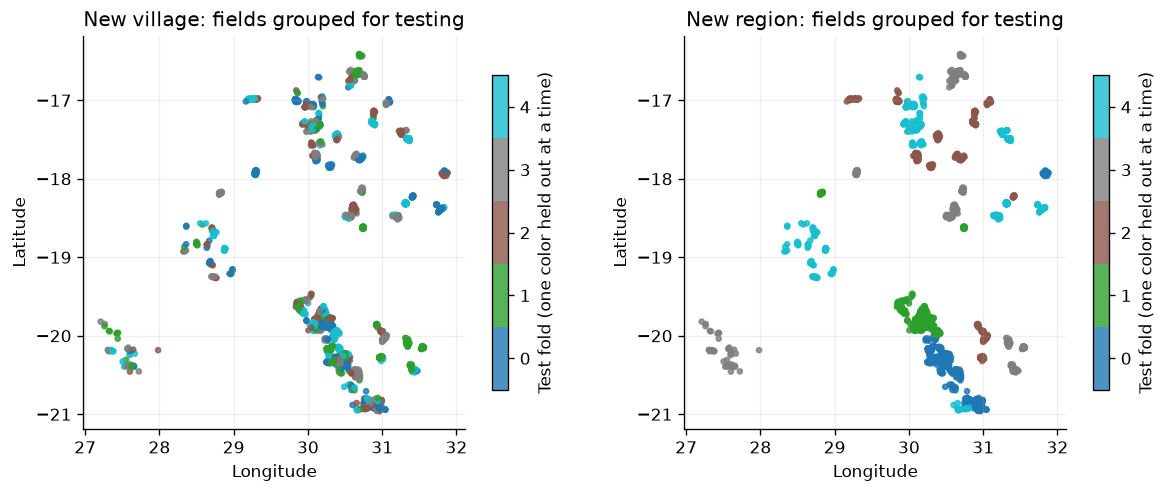

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(10, 4), layout="constrained")
for ax, (family, title) in zip(axes, FAMILIES.items()):
    points = ax.scatter(labels.longitude, labels.latitude, c=splits[family].fold,
                        cmap=plt.get_cmap("tab10", 5), vmin=-0.5, vmax=4.5, s=9, alpha=0.8)
    ax.set(xlabel="Longitude", ylabel="Latitude", title=f"{title}: fields grouped for testing")
    ax.set_aspect(1 / np.cos(np.deg2rad(labels.latitude.mean())))
    fig.colorbar(points, ax=ax, ticks=range(5), label="Test fold (one color held out at a time)", shrink=0.8)
savefig("02_spatial_folds")


## 4. Fit Ridge models without using test information

**Ridge regression** fits a weighted sum of the input columns. Its regularization parameter, **alpha (α)**, controls how strongly the weights are shrunk toward zero. Larger alpha means stronger shrinkage. For every model, inner CV chooses from 25 alpha values and selects the one with the lowest validation error.

Before fitting, we remove columns with no training values, fill remaining gaps with training medians, and standardize the inputs. For vegetation indices, we also limit extreme values using the training data's 1st and 99th percentiles. All these steps are learned again within each training subset; validation and test fields never supply their statistics.

The next cell defines the preprocessing and Ridge helpers. The faster Ridge calculation reuses matrix operations across alpha values; its predictions are checked against scikit-learn's Ridge implementation before we run the comparison.


In [6]:
def prepare(data, train, heldout):
    """Fit all transformations on train, then apply the same transformations to heldout."""
    A, B = data["X"][train].copy(), data["X"][heldout].copy()
    keep = np.isfinite(A).any(axis=0)
    A, B = A[:, keep], B[:, keep]
    if data["clip"] and A.shape[1]:
        lo, hi = np.nanquantile(A, [0.01, 0.99], axis=0)
        A, B = np.clip(A, lo, hi), np.clip(B, lo, hi)
    if A.shape[1]:
        medians = np.nanmedian(A, axis=0)
        A = np.where(np.isnan(A), medians, A)
        B = np.where(np.isnan(B), medians, B)
    if data["flags"] is not None:
        A = np.column_stack([A, data["flags"][train]])
        B = np.column_stack([B, data["flags"][heldout]])
    scaler = StandardScaler()
    A, B = scaler.fit_transform(A), scaler.transform(B)
    assert np.isfinite(A).all() and np.isfinite(B).all()
    return A, B


def ridge_path(A, target, B, alphas):
    """Exact Ridge predictions for all alphas; one decomposition per training subset."""
    center, intercept = A.mean(axis=0), target.mean()
    A, B, target = A - center, B - center, target - intercept
    if A.shape[1] <= A.shape[0]:
        eigenvalues, vectors = eigh(A.T @ A, check_finite=False)
        left = B @ vectors
        right = vectors.T @ (A.T @ target)
    else:
        eigenvalues, vectors = eigh(A @ A.T, check_finite=False)
        left = (B @ A.T) @ vectors
        right = vectors.T @ target
    weights = right[:, None] / (np.maximum(eigenvalues, 0)[:, None] + alphas[None, :])
    return left @ weights + intercept


# Validate the optimized solver, and training-only transformation behavior.
rng = np.random.default_rng(SEED)
for shape in [(45, 9), (25, 80)]:
    A, B = rng.normal(size=shape), rng.normal(size=(7, shape[1]))
    target = rng.normal(size=shape[0])
    alphas = np.array([0.001, 1.0, 1000.0])
    expected = np.column_stack([Ridge(alpha=a, solver="cholesky").fit(A, target).predict(B) for a in alphas])
    np.testing.assert_allclose(ridge_path(A, target, B, alphas), expected, atol=1e-7, rtol=1e-7)
example = {"X": np.array([[0., np.nan], [2., np.nan], [1e9, 100.]]), "flags": None, "clip": False}
A, B = prepare(example, np.array([0, 1]), np.array([2]))
np.testing.assert_allclose(A[:, 0], [-1., 1.])
assert A.shape[1] == 1 and B[0, 0] > 1e8
print("Checks passed: the faster Ridge calculation matches scikit-learn, and preprocessing uses training values only.")


Checks passed: the faster Ridge calculation matches scikit-learn, and preprocessing uses training values only.


**Now we can fit the baselines.** Every model uses the same training, validation, and test fields. After choosing alpha, we refit on all outer training fields and predict the untouched outer test fields. At the end, each field has exactly one test prediction for each model under each geographic test.

We also save a comparison that chooses the input group inside inner CV. We will explain that additional result after the main baseline comparison.


In [7]:
def run_nested(candidate_models, model_order, signal_models, selector_name, stage):
    """Tune on inner folds, then predict outer test folds; use identical splits for every model."""
    y_pred, selections, inner_curves, fold_records = {}, [], [], []
    started = time.perf_counter()

    for family, title in FAMILIES.items():
        split = splits[family]
        folds, groups = split.fold.to_numpy(), split.group_id.to_numpy()
        predictions = {name: np.full(n, np.nan) for name in [*model_order, selector_name]}
        for outer in range(5):
            train, test = np.flatnonzero(folds != outer), np.flatnonzero(folds == outer)
            predictions["Training mean"][test] = y[train].mean()
            inner_folds = [f for f in range(5) if f != outer]
            inner_ids = [(np.flatnonzero((folds != outer) & (folds != f)), np.flatnonzero(folds == f))
                         for f in inner_folds]
            assert all(set(groups[a]).isdisjoint(groups[b]) and not np.intersect1d(test, np.r_[a, b]).size
                       for a, b in inner_ids)
            candidate_scores = {}
            for name, data in candidate_models.items():
                losses = []
                for inner_train, valid in inner_ids:
                    A, B = prepare(data, inner_train, valid)
                    path = ridge_path(A, y[inner_train], B, ALPHAS)
                    losses.append(np.mean((path - y[valid, None]) ** 2, axis=0))
                losses = np.asarray(losses)
                mean_mse = losses.mean(axis=0)
                best = int(mean_mse.argmin())
                alpha = float(ALPHAS[best])
                A, B = prepare(data, train, test)
                fitted = Ridge(alpha=alpha, solver="cholesky").fit(A, y[train])
                predictions[name][test] = fitted.predict(B)
                candidate_scores[name] = mean_mse[best]
                selections.append({"family": family, "outer_fold": outer, "model": name, "alpha": alpha,
                                   "inner_cv_rmse": float(np.sqrt(mean_mse[best])),
                                   "fitted_columns": A.shape[1], "alpha_at_grid_edge": best in [0, len(ALPHAS)-1]})
                inner_curves.extend({"family": family, "outer_fold": outer, "model": name, "alpha": float(a),
                                     "inner_cv_rmse": float(np.sqrt(loss))} for a, loss in zip(ALPHAS, mean_mse))
            chosen = min(signal_models, key=candidate_scores.get)
            predictions[selector_name][test] = predictions[chosen][test]
            chosen_row = next(row for row in reversed(selections) if row["family"] == family and
                              row["outer_fold"] == outer and row["model"] == chosen)
            selections.append({**chosen_row, "model": selector_name, "selected_representation": chosen})
            for name, pred in predictions.items():
                fold_records.append({"family": family, "outer_fold": outer, "model": name, "n_test": len(test),
                                     "rmse": float(np.sqrt(np.mean((pred[test] - y[test])**2)))})
        assert all(np.isfinite(pred).all() for pred in predictions.values())
        y_pred[family] = predictions
        print(f"{stage}: finished {title.lower()}: all five test folds predicted for every model.", flush=True)

    selections = pd.DataFrame(selections)
    inner_curves = pd.DataFrame(inner_curves)
    fold_records = pd.DataFrame(fold_records)


    return y_pred, selections, inner_curves, fold_records


started = time.perf_counter()
y_pred, selections, inner_curves, fold_records = run_nested(models, ORDER, SIGNAL_MODELS, SELECTOR, "Monthly")
print("Monthly test predictions are ready. Let's compare their errors below.")


Monthly: finished new village: all five test folds predicted for every model.


Monthly: finished new region: all five test folds predicted for every model.


Monthly test predictions are ready. Let's compare their errors below.


## 5. Compare prediction accuracy

Each table below combines the held-out predictions for all 1,880 fields. Every row is a model from the input table; each column answers a different question:

- **RMSE (root mean squared error):** how large are the prediction errors, giving extra weight to large mistakes? Lower is better; the unit is t/ha.
- **MAE (mean absolute error):** how far off is a prediction on average? Lower is better; the unit is also t/ha.
- **R²:** how much does the model improve squared error relative to predicting the evaluation sample's mean? One is perfect; negative values mean worse than that reference.
- **Rank correlation (Spearman):** does the model put higher-yield fields above lower-yield fields? Values closer to +1 are better; zero indicates no rank association.

The tables are sorted by RMSE. A lower observed score does not by itself establish that one model is reliably better than another; the next figure shows uncertainty.


In [8]:
def rho(a, b):
    return float(spearmanr(a, b).statistic) if np.ptp(a) > 0 and np.ptp(b) > 0 else np.nan

def summarize_predictions(prediction_sets, model_order, selector_name):
    """Score one outer-test prediction per field and bootstrap whole spatial groups."""
    result_rows, oof_tables = [], []
    for family, predictions in prediction_sets.items():
        split = splits[family]
        group_codes, group_names = pd.factorize(split.group_id)
        sizes = np.bincount(group_codes)
        names = [*model_order, selector_name]
        squared_errors = np.column_stack([(predictions[name] - y)**2 for name in names])
        group_sse = np.zeros((len(sizes), len(names)))
        np.add.at(group_sse, group_codes, squared_errors)
        draws = np.random.default_rng(SEED).multinomial(len(sizes), np.full(len(sizes), 1/len(sizes)), size=N_BOOT)
        boot_rmse = np.sqrt((draws @ group_sse) / (draws @ sizes)[:, None])
        boot_delta = boot_rmse - boot_rmse[:, [0]]
        for j, name in enumerate(names):
            pred = predictions[name]
            group_rhos = [rho(y[group_codes == g], pred[group_codes == g])
                          for g in range(len(sizes)) if sizes[g] >= 10]
            finite_rhos = [v for v in group_rhos if np.isfinite(v)]
            result_rows.append({"family": family, "model": name, "n": n,
                               "rmse": np.sqrt(np.mean((pred-y)**2)), "mae": np.mean(np.abs(pred-y)),
                               "bias": np.mean(pred-y), "r2": 1-np.sum((pred-y)**2)/np.sum((y-y.mean())**2),
                               "spearman": rho(y, pred),
                               "within_group_spearman": np.median(finite_rhos) if finite_rhos else np.nan,
                               "within_group_rho_groups": len(finite_rhos),
                               "rmse_ci_low": np.quantile(boot_rmse[:, j], .025),
                               "rmse_ci_high": np.quantile(boot_rmse[:, j], .975),
                               "delta_rmse_vs_mean": np.sqrt(np.mean((pred-y)**2))-np.sqrt(np.mean(squared_errors[:, 0])),
                               "delta_ci_low": np.quantile(boot_delta[:, j], .025),
                               "delta_ci_high": np.quantile(boot_delta[:, j], .975)})
            oof_tables.append(pd.DataFrame({"obs_id": IDS, "family": family, "outer_fold": split.fold.to_numpy(),
                                            "group_id": split.group_id.to_numpy(), "model": name,
                                            "y_true_t_ha": y, "y_pred_t_ha": pred}))
    results = pd.DataFrame(result_rows)
    oof = pd.concat(oof_tables, ignore_index=True)
    assert oof.groupby(["family", "model"]).size().eq(n).all()
    assert not oof.duplicated(["family", "model", "obs_id"]).any()

    return results, oof


results, oof = summarize_predictions(y_pred, ORDER, SELECTOR)


In [9]:
for family, title in FAMILIES.items():
    table = results.loc[results.family.eq(family) & results.model.isin(ORDER)].sort_values("rmse").copy()
    display(Markdown(f"**{title}: prediction accuracy on held-out fields**"))
    shown = table[["model", "rmse", "mae", "r2", "spearman"]].rename(columns={
        "model": "Model input", "rmse": "RMSE (t/ha) ↓", "mae": "MAE (t/ha) ↓",
        "r2": "R² ↑", "spearman": "Rank correlation ↑"})
    shown["Model input"] = shown["Model input"].map(MODEL_LABELS)
    show_table(shown)
    best = table.iloc[0]
    reference = table.loc[table.model.eq("Training mean"), "rmse"].iloc[0]
    improvement = 100 * (reference - best.rmse) / reference
    display(Markdown(
        f"**What to notice:** {MODEL_LABELS[best.model]} has the lowest observed RMSE here: "
        f"**{best.rmse:.3f} t/ha**, compared with **{reference:.3f} t/ha** for the training mean "
        f"({improvement:.1f}% lower)."))


**New village: prediction accuracy on held-out fields**

Model input,RMSE (t/ha) ↓,MAE (t/ha) ↓,R² ↑,Rank correlation ↑
Ten spectral bands,1.639,1.279,0.326,0.580
All five indices,1.736,1.373,0.244,0.513
MOSAIKS: surrounding image,1.740,1.386,0.240,0.499
MOSAIKS: field pixel,1.743,1.358,0.238,0.544
NDVI,1.749,1.387,0.233,0.490
NDVI705,1.759,1.396,0.224,0.481
GCVI,1.777,1.420,0.208,0.470
NDVI740,1.858,1.505,0.134,0.360
MTCI,1.899,1.538,0.096,0.325
Image availability only,1.992,1.627,0.005,0.010


**What to notice:** Ten spectral bands has the lowest observed RMSE here: **1.639 t/ha**, compared with **2.006 t/ha** for the training mean (18.3% lower).

**New region: prediction accuracy on held-out fields**

Model input,RMSE (t/ha) ↓,MAE (t/ha) ↓,R² ↑,Rank correlation ↑
Ten spectral bands,1.785,1.423,0.201,0.460
NDVI,1.861,1.499,0.131,0.379
NDVI705,1.870,1.510,0.123,0.365
All five indices,1.880,1.520,0.114,0.370
GCVI,1.924,1.558,0.072,0.300
MOSAIKS: field pixel,1.935,1.583,0.061,0.251
NDVI740,1.983,1.622,0.014,0.180
MTCI,2.035,1.665,-0.039,0.067
Training mean,2.107,1.733,-0.113,-0.465
Image availability only,2.136,1.759,-0.144,-0.471


**What to notice:** Ten spectral bands has the lowest observed RMSE here: **1.785 t/ha**, compared with **2.107 t/ha** for the training mean (15.3% lower).

The training-mean model can have a slightly negative R² because each test fold receives the mean of its **training** fields, rather than the evaluation sample's mean.

**How to read the comparison plot:** each dot is a model's RMSE; farther left is better. The gray dashed line marks the training-mean reference. Horizontal bars show approximate 95% uncertainty ranges, calculated by repeatedly resampling whole geographic groups. They describe uncertainty in these saved test predictions; they do not repeat model training.


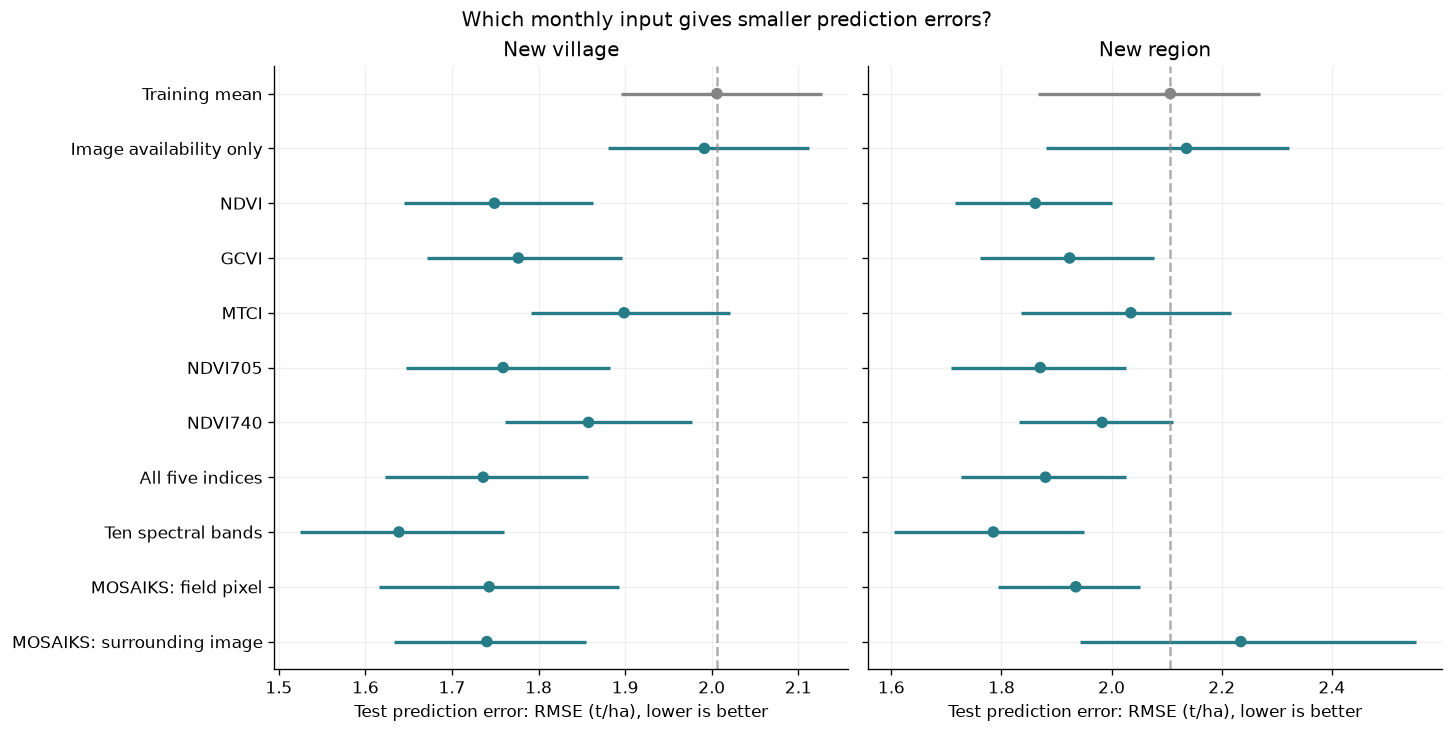

In [10]:
plot_order = ORDER
fig, axes = plt.subplots(1, 2, figsize=(12, 6), sharey=True, layout="constrained")
for ax, (family, title) in zip(axes, FAMILIES.items()):
    rows = results.loc[results.family.eq(family)].set_index("model").loc[plot_order]
    pos = np.arange(len(rows))
    colors = ["#858585" if name == "Training mean" else "#bc673e" if name == SELECTOR else "#267c87"
              for name in plot_order]
    ax.hlines(pos, rows.rmse_ci_low, rows.rmse_ci_high, color=colors, lw=2)
    ax.scatter(rows.rmse, pos, c=colors, s=35, zorder=3)
    ax.axvline(rows.loc["Training mean", "rmse"], color="#858585", linestyle="--", alpha=.65)
    ax.set(xlabel="Test prediction error: RMSE (t/ha), lower is better", title=title, yticks=pos, yticklabels=[MODEL_LABELS[name] for name in plot_order])
axes[0].invert_yaxis()
fig.suptitle("Which monthly input gives smaller prediction errors?")
savefig("03_nested_cv_rmse")


Among the monthly models, the ten spectral bands have the smallest observed errors under both tests. Surrounding-image MOSAIKS performs much worse when whole regions are held out; the field-pixel version transfers better in this comparison. More image features do not automatically give better predictions.


## 6. Look at the predictions, not just the scores

Let's examine the ten-band model, which had the lowest observed RMSE among the monthly models. These charts use its existing held-out predictions; no model is refitted here.

On the **left**, observed yield is on the horizontal axis and predicted yield is on the vertical axis. Perfect predictions lie on the dashed diagonal. On the **right**, an error above zero means overprediction; an error below zero means underprediction. Brighter hexagons contain more fields.


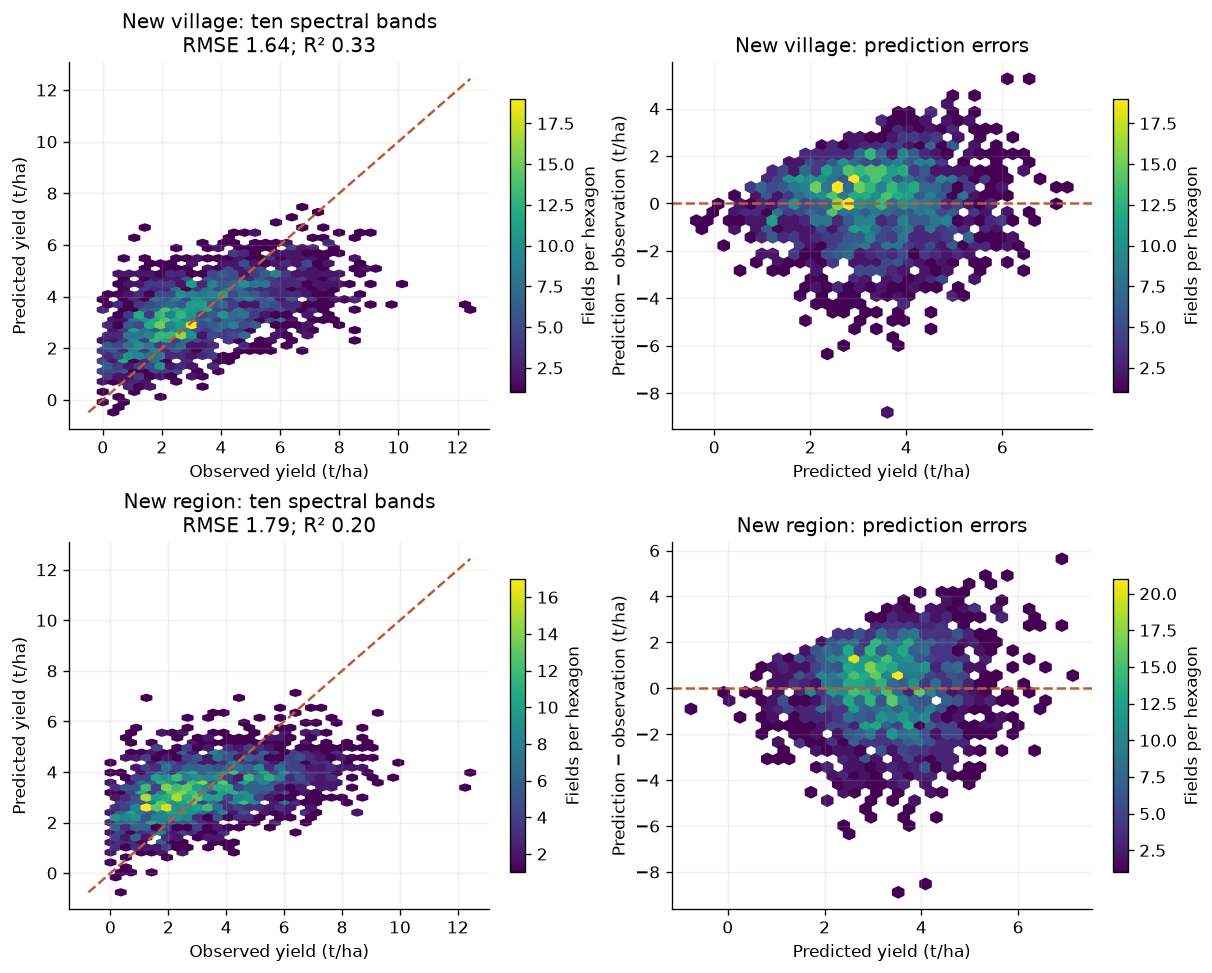

In [11]:
fig, axes = plt.subplots(2, 2, figsize=(10, 8), layout="constrained")
for row, (family, title) in enumerate(FAMILIES.items()):
    pred = y_pred[family]["Monthly bands"]
    score = results.loc[results.family.eq(family) & results.model.eq("Monthly bands")].iloc[0]
    density = axes[row, 0].hexbin(y, pred, gridsize=35, mincnt=1, cmap="viridis")
    fig.colorbar(density, ax=axes[row, 0], label="Fields per hexagon", shrink=0.8)
    lo, hi = min(y.min(), pred.min()), max(y.max(), pred.max())
    axes[row, 0].plot([lo, hi], [lo, hi], color="#be5b37", linestyle="--")
    axes[row, 0].set(xlabel="Observed yield (t/ha)", ylabel="Predicted yield (t/ha)",
                     title=f"{title}: ten spectral bands\nRMSE {score.rmse:.2f}; R² {score.r2:.2f}")
    density = axes[row, 1].hexbin(pred, pred-y, gridsize=35, mincnt=1, cmap="viridis")
    fig.colorbar(density, ax=axes[row, 1], label="Fields per hexagon", shrink=0.8)
    axes[row, 1].axhline(0, color="#be5b37", linestyle="--")
    axes[row, 1].set(xlabel="Predicted yield (t/ha)", ylabel="Prediction − observation (t/ha)",
                     title=f"{title}: prediction errors")
savefig("04_predictions_and_residuals")


The model captures some of the yield variation, but high-yield fields are often underestimated. Its predictions are more concentrated near the middle than the observed yields. This matters even when the average error is better than the training-mean reference.


## 7. See how cross-validation chose alpha

The following curves show **inner validation error**, not test error. They use the first outer training round of the new-region test as an example. Each dot corresponds to one alpha value; the orange dot marks the selected value. The horizontal axis uses a logarithmic scale, so equal steps represent multiplication rather than addition.

Different input groups can need very different shrinkage strengths. This is why we select alpha separately for every model and every outer training round.


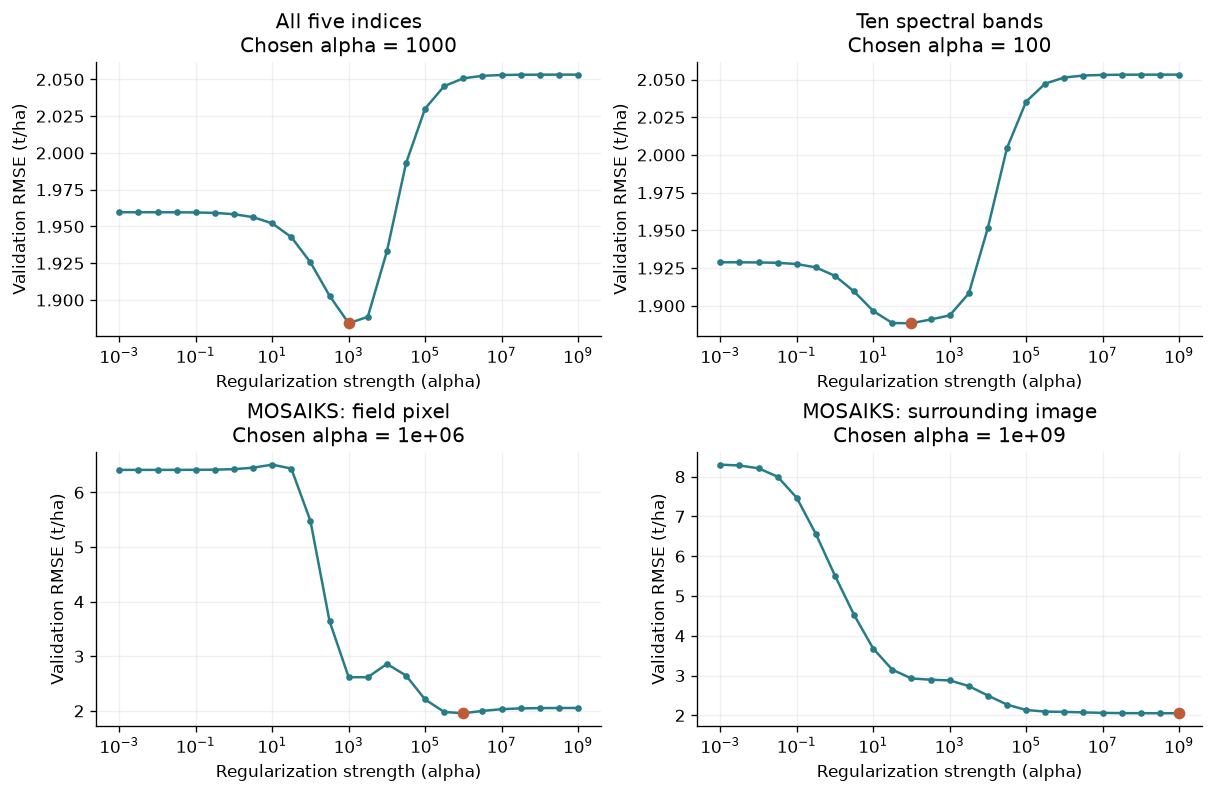

In [12]:
curve_models = ["All indices monthly", "Monthly bands", "MOSAIKS field monthly", "MOSAIKS chip monthly"]
fig, axes = plt.subplots(2, 2, figsize=(10, 6.5), layout="constrained")
for ax, name in zip(axes.flat, curve_models):
    curve = inner_curves.loc[inner_curves.family.eq("s2_region") & inner_curves.outer_fold.eq(0)
                             & inner_curves.model.eq(name)].sort_values("alpha")
    best = curve.loc[curve.inner_cv_rmse.idxmin()]
    ax.semilogx(curve.alpha, curve.inner_cv_rmse, marker=".", color="#267c87")
    ax.scatter([best.alpha], [best.inner_cv_rmse], color="#be5b37", zorder=3)
    ax.set(xlabel="Regularization strength (alpha)", ylabel="Validation RMSE (t/ha)", title=f"{MODEL_LABELS[name]}\nChosen alpha = {best.alpha:g}")
savefig("05_inner_cv_tuning")


In [13]:
edge = selections.loc[selections.model.ne(SELECTOR) & selections.alpha_at_grid_edge]
print(f"In {len(edge)} of 100 Ridge fits, CV chose an endpoint of the alpha grid.")
print("Those choices are limited by the tested range: a very small alpha is nearly unregularized,")
print("while a very large alpha makes predictions approach the training mean.")


In 10 of 100 Ridge fits, CV chose an endpoint of the alpha grid.
Those choices are limited by the tested range: a very small alpha is nearly unregularized,
while a very large alpha makes predictions approach the training mean.


## 8. Optional check: let CV choose the input group too

The main tables evaluate each input group separately. We also tested a selection procedure: within each outer training round, inner CV chooses **both the satellite input group and alpha**. The outer test fields have no say in either choice.

The small table below evaluates that complete selection procedure. It can differ from the ten-band model because inner CV may choose another input group in some rounds.


In [14]:
selected_results = results.loc[results.model.eq(SELECTOR), ["family", "rmse", "r2", "spearman"]].copy()
selected_results["family"] = selected_results["family"].map(FAMILIES)
selected_results = selected_results.rename(columns={"family": "Geographic test", "rmse": "RMSE (t/ha) ↓",
                                                     "r2": "R² ↑", "spearman": "Rank correlation ↑"})
show_table(selected_results)
for family, title in FAMILIES.items():
    choices = selections.loc[selections.family.eq(family) & selections.model.eq(SELECTOR),
                              "selected_representation"].value_counts()
    description = "; ".join(f"{MODEL_LABELS[name]} in {count} of 5 rounds" for name, count in choices.items())
    display(Markdown(f"**{title}:** inner CV chose {description}."))


Geographic test,RMSE (t/ha) ↓,R² ↑,Rank correlation ↑
New village,1.639,0.326,0.580
New region,1.826,0.164,0.421


**New village:** inner CV chose Ten spectral bands in 5 of 5 rounds.

**New region:** inner CV chose Ten spectral bands in 4 of 5 rounds; NDVI705 in 1 of 5 rounds.

## 9. Add seasonal inputs: summarize the available months

Do we need the month-by-month detail, or can a smaller set of summaries predict yield just as well? Let's keep the **same 1,880 fields, yield targets, and nested CV splits**, and change only the input representation.

Here, **seasonal** means one summary vector for the October 2022–June 2023 window. We use only observed values; a missing month is not treated as zero.

- **Each vegetation index:** its maximum and mean over available months, giving two values. All five indices together give ten values.
- **Spectral bands:** the maximum and mean of each of the ten bands, giving twenty values.
- **MOSAIKS:** the average monthly feature vector, separately for the field pixel and surrounding image; each has 1,024 values.
- **Presto:** the stored 128-value embedding from a pretrained satellite encoder. This is an additional whole-season benchmark, not a simple mean/max summary. There is no matching monthly Presto representation in this database.

We also include the training mean and a **clear-month count** as references. For matched satellite comparisons, each seasonal model receives the same monthly availability indicators as its monthly counterpart. This keeps information about missing images consistent. Fields with cloud gaps may still summarize different sets of months.


In [15]:
SEASON_COLUMNS = [f"{index}_season_{stat}" for index in INDICES for stat in ["max", "mean"]]
with duckdb.connect(str(DB), read_only=True) as con:
    season_rows = con.execute(f"""
        SELECT obs_id, yield_kg_ha / 1000.0 AS yield_t_ha, {', '.join(SEASON_COLUMNS)},
               presto_embedding, mosaiks_field, mosaiks_chip
        FROM master WHERE cohort = ? AND year = 2023 AND include_primary
        ORDER BY obs_id
    """, [COHORT]).df().set_index("obs_id").loc[IDS]
np.testing.assert_allclose(season_rows.yield_t_ha.to_numpy(), y)
seasonal_models = {}


def add_seasonal(name, values, columns, availability=None, clip=False):
    X = np.array(values, dtype=float, copy=True)
    X[~np.isfinite(X)] = np.nan
    assert X.shape == (n, len(columns))
    seasonal_models[name] = {"X": X, "flags": availability, "clip": clip, "columns": columns}


for j, index in enumerate(INDICES):
    columns = [f"{index}_season_max", f"{index}_season_mean"]
    add_seasonal(f"{index.upper()} seasonal", season_rows[columns], columns,
                 models[f"{index.upper()} monthly"]["flags"], clip=True)
    # Check that the saved summaries really are the max and mean of the monthly values.
    values = models[f"{index.upper()} monthly"]["X"].reshape(n, m)
    np.testing.assert_allclose(season_rows[columns].to_numpy(),
                               np.column_stack([np.nanmax(values, axis=1), np.nanmean(values, axis=1)]))

add_seasonal("All indices seasonal", season_rows[SEASON_COLUMNS], SEASON_COLUMNS,
             models["All indices monthly"]["flags"], clip=True)
band_values = models["Monthly bands"]["X"].reshape(n, m, len(BANDS))
band_summaries = np.stack([np.nanmax(band_values, axis=1), np.nanmean(band_values, axis=1)], axis=-1)
add_seasonal("Spectral bands seasonal", band_summaries.reshape(n, -1),
             [f"{band}_season_{stat}" for band in BANDS for stat in ["max", "mean"]],
             models["Monthly bands"]["flags"])

for column, name, monthly_name in [
    ("mosaiks_field", "MOSAIKS field seasonal", "MOSAIKS field monthly"),
    ("mosaiks_chip", "MOSAIKS chip seasonal", "MOSAIKS chip monthly")]:
    vectors = np.stack(season_rows[column].to_list())
    monthly_vectors = models[monthly_name]["X"].reshape(n, m, 1024)
    np.testing.assert_allclose(vectors, np.nanmean(monthly_vectors, axis=1), rtol=1e-5, atol=2e-6)
    add_seasonal(name, vectors, [f"{column}_{j:04d}" for j in range(1024)], models[monthly_name]["flags"])

presto = np.stack(season_rows.presto_embedding.to_list())
add_seasonal("Presto whole season", presto, [f"presto_{j:03d}" for j in range(128)], band_flags)
add_seasonal("Clear-month count", band_flags.sum(axis=1, keepdims=True), ["clear_months"])
SEASON_ORDER = ["Training mean", "Clear-month count", *[f"{index.upper()} seasonal" for index in INDICES],
                "All indices seasonal", "Spectral bands seasonal", "MOSAIKS field seasonal",
                "MOSAIKS chip seasonal", "Presto whole season"]
SEASON_SELECTOR = "CV-selected seasonal"
seasonal_models = {name: seasonal_models[name] for name in SEASON_ORDER if name != "Training mean"}
SEASON_SIGNALS = [name for name in seasonal_models if name != "Clear-month count"]
MODEL_LABELS.update({
    "Clear-month count": "Clear-month count",
    **{f"{index.upper()} seasonal": index.upper() for index in INDICES},
    "All indices seasonal": "All five indices",
    "Spectral bands seasonal": "Ten spectral bands",
    "MOSAIKS field seasonal": "MOSAIKS: field pixel",
    "MOSAIKS chip seasonal": "MOSAIKS: surrounding image",
    "Presto whole season": "Presto: whole-season embedding",
    SEASON_SELECTOR: "Seasonal input chosen by inner CV",
})
seasonal_inventory = pd.DataFrame([
    {"model": name, "signal_columns": data["X"].shape[1],
     "availability_flags": 0 if data["flags"] is None else data["flags"].shape[1],
     "training_percentile_clip": data["clip"]} for name, data in seasonal_models.items()
])
print("Checks passed: seasonal inputs use the same fields and yields as the monthly models.")
print("Saved index and MOSAIKS summaries agree with the available monthly measurements.")


Checks passed: seasonal inputs use the same fields and yields as the monthly models.
Saved index and MOSAIKS summaries agree with the available monthly measurements.


**Fit and evaluate.** We reuse the same preprocessing and nested CV functions: alpha is chosen inside each outer training round, then the model predicts the held-out fields. No seasonal feature group is chosen using test scores.


In [16]:
seasonal_predictions, seasonal_parameters, seasonal_curves, seasonal_fold_records = run_nested(
    seasonal_models, SEASON_ORDER, SEASON_SIGNALS, SEASON_SELECTOR, "Seasonal")
seasonal_results, seasonal_oof = summarize_predictions(seasonal_predictions, SEASON_ORDER, SEASON_SELECTOR)

# One row per seasonal model; the columns separate the two geographic tests.
village = seasonal_results.loc[seasonal_results.family.eq("s1_cc2km")].set_index("model")
region = seasonal_results.loc[seasonal_results.family.eq("s2_region")].set_index("model")
seasonal_table = pd.DataFrame({
    "Seasonal input": [MODEL_LABELS[name] for name in SEASON_ORDER],
    "New village RMSE": village.loc[SEASON_ORDER, "rmse"].to_numpy(),
    "New region RMSE": region.loc[SEASON_ORDER, "rmse"].to_numpy(),
    "New village R²": village.loc[SEASON_ORDER, "r2"].to_numpy(),
    "New region R²": region.loc[SEASON_ORDER, "r2"].to_numpy(),
})
display(Markdown("**Seasonal model accuracy.** Each row is one input group. RMSE is in t/ha (lower is better); R² is higher when predictions explain more yield variation. Other scores are saved in `seasonal_metrics.csv`."))
show_table(seasonal_table.sort_values("New region RMSE"))
for family, title in FAMILIES.items():
    fixed = seasonal_results.loc[seasonal_results.family.eq(family) & seasonal_results.model.isin(SEASON_ORDER)]
    best = fixed.loc[fixed.rmse.idxmin()]
    display(Markdown(f"**{title}:** the lowest observed seasonal RMSE is **{best.rmse:.3f} t/ha** "
                     f"using **{MODEL_LABELS[best.model]}**."))


Seasonal: finished new village: all five test folds predicted for every model.


Seasonal: finished new region: all five test folds predicted for every model.


**Seasonal model accuracy.** Each row is one input group. RMSE is in t/ha (lower is better); R² is higher when predictions explain more yield variation. Other scores are saved in `seasonal_metrics.csv`.

Seasonal input,New village RMSE,New region RMSE,New village R²,New region R²
Presto: whole-season embedding,1.691,1.836,0.282,0.155
NDVI705,1.799,1.896,0.188,0.098
MOSAIKS: field pixel,1.719,1.902,0.259,0.093
All five indices,1.785,1.904,0.201,0.091
GCVI,1.836,1.937,0.154,0.059
NDVI,1.857,1.953,0.135,0.044
Ten spectral bands,1.767,1.956,0.217,0.041
NDVI740,1.912,2.050,0.083,-0.054
Training mean,2.006,2.107,-0.009,-0.113
Clear-month count,2.013,2.123,-0.016,-0.130


**New village:** the lowest observed seasonal RMSE is **1.691 t/ha** using **Presto: whole-season embedding**.

**New region:** the lowest observed seasonal RMSE is **1.836 t/ha** using **Presto: whole-season embedding**.

**How to read the seasonal comparison:** each dot is the model's held-out RMSE; farther left is better. The gray dashed line is the training-mean reference. As before, the bars show approximate 95% ranges obtained by resampling whole geographic groups. Presto is shown here as a whole-season encoder, not as an average of monthly Presto values.


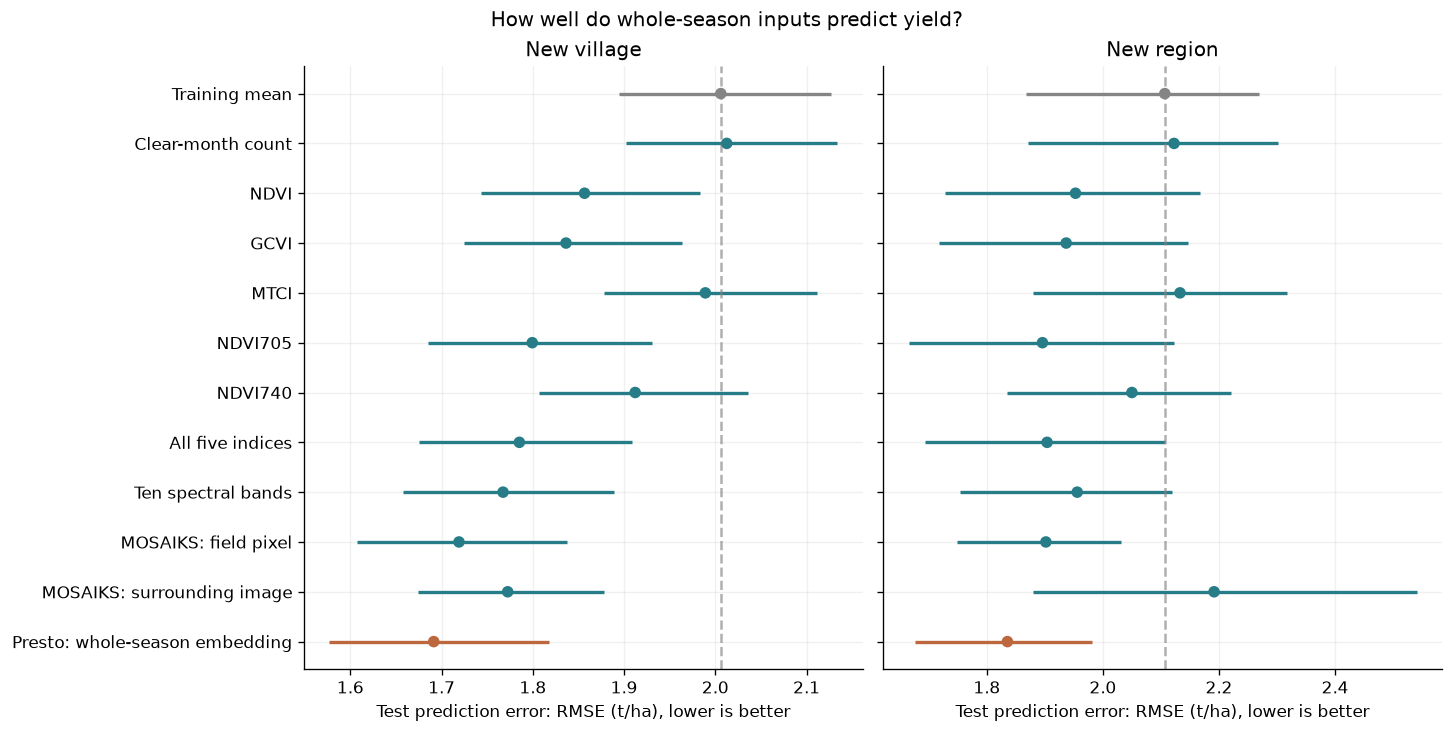

In [17]:
fig, axes = plt.subplots(1, 2, figsize=(12, 6), sharey=True, layout="constrained")
for ax, (family, title) in zip(axes, FAMILIES.items()):
    rows = seasonal_results.loc[seasonal_results.family.eq(family)].set_index("model").loc[SEASON_ORDER]
    positions = np.arange(len(rows))
    colors = ["#858585" if name == "Training mean" else "#bc673e" if name == "Presto whole season"
              else "#267c87" for name in SEASON_ORDER]
    ax.hlines(positions, rows.rmse_ci_low, rows.rmse_ci_high, color=colors, lw=2)
    ax.scatter(rows.rmse, positions, c=colors, s=35, zorder=3)
    ax.axvline(rows.loc["Training mean", "rmse"], color="#858585", linestyle="--", alpha=.65)
    ax.set(xlabel="Test prediction error: RMSE (t/ha), lower is better", title=title,
           yticks=positions, yticklabels=[MODEL_LABELS[name] for name in SEASON_ORDER])
axes[0].invert_yaxis()
fig.suptitle("How well do whole-season inputs predict yield?")
savefig("06_seasonal_rmse")


## 10. Does summarizing the season help?

Now compare each seasonal summary with its **matching monthly input group**. Both versions use the same test fields and availability indicators. Presto has no monthly counterpart here, so it is excluded from this paired comparison.

The plot below shows **seasonal RMSE minus monthly RMSE**. A point **left of zero** favors the seasonal summary; a point **right of zero** favors the monthly inputs. The bars use paired resampling of the same geographic groups. If a bar crosses zero, these results do not clearly distinguish the two versions for that input group.


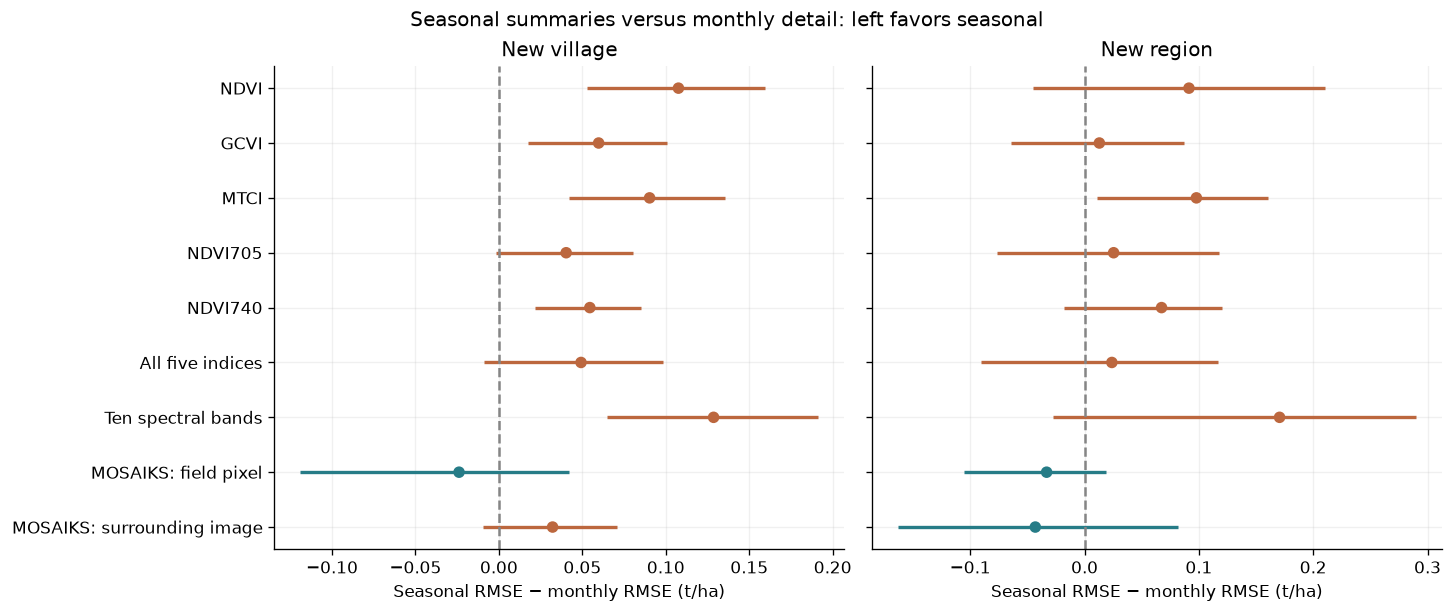

**New village:** seasonal summaries have lower observed RMSE in **1 of 9** matched input groups. The paired 95% ranges favor seasonal inputs for **none**, and monthly inputs for **NDVI, GCVI, MTCI, NDVI740, Ten spectral bands**; the other ranges cross zero.

**New region:** seasonal summaries have lower observed RMSE in **2 of 9** matched input groups. The paired 95% ranges favor seasonal inputs for **none**, and monthly inputs for **MTCI**; the other ranges cross zero.

In [18]:
PAIRS = [(f"{index.upper()} monthly", f"{index.upper()} seasonal", index.upper()) for index in INDICES]
PAIRS += [("All indices monthly", "All indices seasonal", "All five indices"),
          ("Monthly bands", "Spectral bands seasonal", "Ten spectral bands"),
          ("MOSAIKS field monthly", "MOSAIKS field seasonal", "MOSAIKS: field pixel"),
          ("MOSAIKS chip monthly", "MOSAIKS chip seasonal", "MOSAIKS: surrounding image")]
comparison_rows = []
for family in FAMILIES:
    codes, _ = pd.factorize(splits[family].group_id)
    sizes = np.bincount(codes)
    draws = np.random.default_rng(SEED).multinomial(len(sizes), np.full(len(sizes), 1/len(sizes)), size=N_BOOT)
    sampled_n = draws @ sizes
    for monthly_name, seasonal_name, label in PAIRS:
        month_pred, season_pred = y_pred[family][monthly_name], seasonal_predictions[family][seasonal_name]
        month_sse = np.bincount(codes, weights=(month_pred-y)**2)
        season_sse = np.bincount(codes, weights=(season_pred-y)**2)
        delta_draws = np.sqrt((draws @ season_sse)/sampled_n) - np.sqrt((draws @ month_sse)/sampled_n)
        monthly_rmse = np.sqrt(np.mean((month_pred-y)**2))
        seasonal_rmse = np.sqrt(np.mean((season_pred-y)**2))
        comparison_rows.append({"family": family, "input_group": label,
                                "monthly_model": monthly_name, "seasonal_model": seasonal_name,
                                "monthly_rmse": monthly_rmse, "seasonal_rmse": seasonal_rmse,
                                "delta_rmse": seasonal_rmse-monthly_rmse,
                                "delta_ci_low": np.quantile(delta_draws, .025),
                                "delta_ci_high": np.quantile(delta_draws, .975),
                                "monthly_signal_columns": models[monthly_name]["X"].shape[1],
                                "seasonal_signal_columns": seasonal_models[seasonal_name]["X"].shape[1]})
seasonal_comparison = pd.DataFrame(comparison_rows)

fig, axes = plt.subplots(1, 2, figsize=(12, 5), sharey=True, layout="constrained")
for ax, (family, title) in zip(axes, FAMILIES.items()):
    rows = seasonal_comparison.loc[seasonal_comparison.family.eq(family)]
    pos = np.arange(len(rows))
    colors = ["#267c87" if value < 0 else "#bc673e" for value in rows.delta_rmse]
    ax.hlines(pos, rows.delta_ci_low, rows.delta_ci_high, color=colors, lw=2)
    ax.scatter(rows.delta_rmse, pos, c=colors, s=35, zorder=3)
    ax.axvline(0, color="#858585", linestyle="--")
    ax.set(xlabel="Seasonal RMSE − monthly RMSE (t/ha)", title=title,
           yticks=pos, yticklabels=rows.input_group)
axes[0].invert_yaxis()
fig.suptitle("Seasonal summaries versus monthly detail: left favors seasonal")
savefig("07_monthly_vs_seasonal")

for family, title in FAMILIES.items():
    rows = seasonal_comparison.loc[seasonal_comparison.family.eq(family)]
    clearer_seasonal = rows.loc[rows.delta_ci_high.lt(0), "input_group"].tolist()
    clearer_monthly = rows.loc[rows.delta_ci_low.gt(0), "input_group"].tolist()
    display(Markdown(f"**{title}:** seasonal summaries have lower observed RMSE in "
                     f"**{rows.delta_rmse.lt(0).sum()} of {len(rows)}** matched input groups. "
                     f"The paired 95% ranges favor seasonal inputs for "
                     f"**{', '.join(clearer_seasonal) or 'none'}**, and monthly inputs for "
                     f"**{', '.join(clearer_monthly) or 'none'}**; the other ranges cross zero."))


**Takeaway:** Monthly spectral bands retain the lowest observed RMSE overall. Presto is the strongest whole-season benchmark here. Averaging field-pixel MOSAIKS gives slightly smaller errors than its monthly version in both geographic tests, but the paired uncertainty ranges cross zero, so that improvement is not clear-cut.

**What this comparison can tell us:** seasonal summaries use fewer signal columns and discard the month labels. They may reduce noise, but they can also lose useful growth timing. The comparison shows which tradeoff worked better here; it does not establish why a model improved. Averages and maxima are calculated before the training-only preprocessing described in Section 4.

The uncertainty ranges are conditional on these saved test predictions, and we have not adjusted them for comparing several input groups. Keep the two geographic tests separate: success in new villages does not guarantee success in new regions or a new harvest year.


## 11. Keep the results for later comparisons

The code below saves both monthly and seasonal scores, individual test predictions, selected alpha values, and figures alongside a record of the data and software versions. The original `data_overview.ipynb` is not changed.

These results describe the 2023 sample under geographic holdouts. The inputs extend through June 2023, so this evaluates full-window yield estimates; predicting before harvest would require an earlier cutoff for every model. MOSAIKS is evaluated using the stored image features, without rebuilding its random filters.


In [19]:
results.to_csv(OUT / "metrics.csv", index=False)
oof.to_csv(OUT / "outer_predictions.csv", index=False)
selections.to_csv(OUT / "selected_parameters.csv", index=False)
inner_curves.to_csv(OUT / "inner_cv_curves.csv", index=False)
fold_records.to_csv(OUT / "outer_fold_diagnostics.csv", index=False)
pd.DataFrame(inventory).to_csv(OUT / "feature_inventory.csv", index=False)
pd.DataFrame(split_audit).to_csv(OUT / "split_audit.csv", index=False)
run_manifest = {
    "cohort": COHORT, "harvest_year": 2023, "n": n, "target": "yield_t_ha", "months": MONTHS,
    "alpha_grid": ALPHAS.tolist(), "inner_scoring": "mean fold MSE", "outer_folds": 5, "inner_folds": 4,
    "inner_split_rule": "remaining frozen outer folds, one at a time", "bootstrap_draws": N_BOOT,
    "seed": SEED, "database": str(DB.relative_to(ROOT)), "database_size_bytes": DB.stat().st_size,
    "database_build": json.loads(build_info.to_json(orient="records", date_format="iso")),
    "labels_sha256": hashlib.sha256((ROOT / "data/processed/labels_v1.parquet").read_bytes()).hexdigest(),
    "obs_ids_sha256": hashlib.sha256("\n".join(IDS).encode()).hexdigest(),
    "split_sha256": {f: manifest["files"][f"{COHORT}__{f}.csv"]["sha256"] for f in FAMILIES},
    "preprocessing": "training-only all-missing removal, index 1/99 percentile clipping, median imputation, availability flags, StandardScaler",
    "feature_columns": {name: data["columns"] for name, data in models.items()},
    "versions": {"python": platform.python_version(), "numpy": np.__version__, "pandas": pd.__version__,
                 "scipy": scipy.__version__, "scikit-learn": sklearn.__version__, "duckdb": duckdb.__version__},
    "runtime_seconds": time.perf_counter()-started,
}
(OUT / "run_manifest.json").write_text(json.dumps(run_manifest, indent=2) + "\n")


seasonal_results.to_csv(OUT / "seasonal_metrics.csv", index=False)
seasonal_oof.to_csv(OUT / "seasonal_outer_predictions.csv", index=False)
seasonal_parameters.to_csv(OUT / "seasonal_selected_parameters.csv", index=False)
seasonal_curves.to_csv(OUT / "seasonal_inner_cv_curves.csv", index=False)
seasonal_fold_records.to_csv(OUT / "seasonal_outer_fold_diagnostics.csv", index=False)
seasonal_inventory.to_csv(OUT / "seasonal_feature_inventory.csv", index=False)
seasonal_comparison.to_csv(OUT / "monthly_vs_seasonal.csv", index=False)
combined_metrics = pd.concat([results.assign(representation="monthly"),
                              seasonal_results.assign(representation="seasonal")], ignore_index=True)
combined_metrics.to_csv(OUT / "combined_metrics.csv", index=False)
run_manifest["seasonal_analysis"] = {
    "models": SEASON_ORDER, "feature_columns": {name: data["columns"] for name, data in seasonal_models.items()},
    "aggregation": "index max/mean, band max/mean, stored MOSAIKS means, stored Presto whole-season embedding",
    "availability": "same month flags as matched monthly model; band flags for Presto",
    "pairing": "same obs_id, target, outer folds, inner folds, and alpha grid",
}
(OUT / "run_manifest.json").write_text(json.dumps(run_manifest, indent=2) + "\n")
print("Saved monthly and seasonal comparison results, plus seven figures, in notebook/baseline_results/.")


Saved monthly and seasonal comparison results, plus seven figures, in notebook/baseline_results/.


The key files are:

- [Model scores](baseline_results/metrics.csv): all accuracy measures and uncertainty intervals, including the extra diagnostics omitted from the main tables.
- [Individual test predictions](baseline_results/outer_predictions.csv): observed and predicted yield for every field, model, and geographic test.
- [Chosen model settings](baseline_results/selected_parameters.csv): the alpha selected in each outer training round, plus the input group chosen by the selection procedure.

The seasonal additions are saved separately:

- [Seasonal model scores](baseline_results/seasonal_metrics.csv): accuracy measures for the whole-season inputs.
- [Monthly versus seasonal](baseline_results/monthly_vs_seasonal.csv): paired errors and uncertainty ranges for each matched input group.
- [All model scores](baseline_results/combined_metrics.csv): monthly and seasonal results together, labeled by representation.

For your next comparison, keep the same fields and geographic splits. Use both the monthly and seasonal results as references; choosing a final model after inspecting these test results would need further independent evaluation.

Implementation details: [Ridge regression](https://scikit-learn.org/stable/modules/generated/sklearn.linear_model.Ridge.html), [nested cross-validation](https://scikit-learn.org/stable/auto_examples/model_selection/plot_nested_cross_validation_iris.html), and [training-only preprocessing](https://scikit-learn.org/stable/common_pitfalls.html). The project's split definitions are in `docs/EVALUATION.md`.
